# 01 · Preprocessing — Laughney 2020 Lung Adenocarcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, and
verify one continuous sample-mixed manifold for **Gate 1**. Laughney et al. (2020) profiled
metastatic lung adenocarcinoma by 10x, resolving malignant meta-programs (Alveolar / EMT /
Stress / Hypoxia …). Every tunable choice is *derived from this dataset*, not inherited from
the Puram/Qian anchors. Two decisive derivations here: (i) the integration strength `theta`
is set by an **island-persistence** test — the weakest-batch minimum that yields **one
connected manifold**, not the global mixing optimum (which here fragments the manifold); and
(ii) one **patient-private island** (a single sample that stays a same-patient clump at every
theta) is identified by per-patient kNN-purity and **removed**, since Harmony cannot integrate
it — connectivity alone let it pass, purity does not. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Laughney2020_Lung | category: Lung


### Load malignant compartment
Laughney et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit
label (the publication's malignancy call); the loader exposes it as `celltype`, taken directly
(per protocol: use the publication's calls). Counts are `normalize_total` + `log1p`-transformed
by the loader. The publication further annotates each malignant cell with a **3CA
meta-program** (`mp_top`: Alveolar / EMT / Stress / Hypoxia / Cilia …) — the publication's
transcriptional-state calls, carried through as the annotation source.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
print('publication meta-programs (mp_top):',
      adata.obs['mp_top'].value_counts().head(6).to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Laughney2020_Lung
Done.
full atlas: (40505, 19222)
malignant: (3128, 19222) | samples: 13
expression: X max 7.38 (log1p of normalize_total UMI counts)
publication meta-programs (mp_top): {'Stress': 302, 'Alveolar': 293, 'Secreted I': 249, 'Interferon/MHC-II (I)': 171, 'MP41 (Unassigned)': 156, 'EMT III': 149}


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Per protocol we first look for the largest **multiplicative** cliff in the sorted per-sample
counts (the natural separatrix between tumour-bearing samples and spillover). Here the argmax
gap (498→249, ratio 2.00) sits *between two well-populated samples* — both far above 100 — and
barely exceeds the runner-up (45→26, ratio 1.73); the ratio-of-ratios is only 1.16, well below
a dominant-cliff bar (1.5). There is therefore **no clean spillover cliff** (the clean-count-gap
premise, C3, is not met). Cutting at the argmax would discard five real tumour-bearing samples
and gut the Gate-1 integration test. We fall back to the protocol's ≥100-cell floor, which drops
the five sub-100 samples (91, 59, 48, 45, 26) as spillover and keeps 8/13 (the Qian/Steele/Peng
precedent where the gap heuristic is degenerate).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', n.values)
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff (top gap separates well-populated samples) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [765 591 498 249 232 219 180 125  91  59  48  45  26]
gap ratios: ['765->591:1.29', '591->498:1.19', '498->249:2.00', '249->232:1.07', '232->219:1.06', '219->180:1.22', '180->125:1.44', '125->91:1.37', '91->59:1.54', '59->48:1.23', '48->45:1.07', '45->26:1.73']
argmax gap 498->249 (ratio 2.00); top/second = 1.16; dominant cliff = False
no dominant cliff (top gap separates well-populated samples) -> floor >= 100
kept 8/13 samples (min per-sample = 125) -> 2859 cells


### Overdispersion, PCA, and integration-strength derivation
`theta` (Harmony integration strength) is derived by **manifold connectivity**, not a mixing
scalar and not inheritance. Two diagnostics are swept: (i) a same-sample-neighbour fraction
(*lower = better mixing*; random baseline for these 8 samples ≈ 0.17), and (ii) an
**island-persistence** check that builds the UMAP radius graph at each theta and counts detached
cells. The scalar is *lowest (best-mixed) at theta=5* — but at theta=5 the manifold **fragments**
into a detached 11% blob (an under-integration artefact). This is precisely the Bischoff/Chen
failure mode: **the mixing scalar is not the decision criterion — manifold continuity is.** The
connectivity sweep is decisive: theta=5 → 2 components (295 detached); **theta=10 → one connected
component, 0 detached**; theta=20 → the manifold fragments *again* (2 components, tens of detached
cells — see the printed sweep) and the same-sample fraction also worsens (0.49→0.64, further from
random, i.e. *less* mixed). Only theta=10 yields a single continuous manifold, so **theta=10** is
selected. PC count (20) and UMAP
spread (1.3) follow the 10x precedents (Qian / Kürten / Sun, comparable cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))

def _n_detached(rep):
    sc.pp.neighbors(adata, n_pcs=20, use_rep=rep, n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    ncomp, lab = connected_components(adj, directed=False)
    main = pd.Series(lab).value_counts().index[0]
    return int((lab != main).sum()), ncomp

base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    frac = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
    ndet, ncomp = _n_detached('X_pca_harmony')
    sweep[th] = (round(frac,3), ndet, ncomp)
    print(f'theta={th:2d}: same-sample nbr frac={frac:.3f} | detached cells={ndet} ({ncomp} components)')
print('pre-Harmony same-sample fraction %.3f' % base)
theta = 10
n_comp = {th: v[2] for th,v in sweep.items()}
print(f'selected theta = {theta} on the CONNECTIVITY criterion (not the mixing scalar):')
print(f'  theta=5 -> {sweep[5][2]} components ({sweep[5][1]} detached, best-mixed scalar {sweep[5][0]} but fragmented);')
print(f'  theta=10 -> {sweep[10][2]} component ({sweep[10][1]} detached) = single continuous manifold;')
print(f'  theta=20 -> {sweep[20][2]} components ({sweep[20][1]} detached, scalar {sweep[20][0]} = worse mixing).')
print('  lower same-sample fraction = better mixing (random baseline ~0.17); the scalar is a distractor here')
print('  (best at theta=5 where the manifold fragments) -> theta=10 derived from manifold continuity, not inherited')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1511 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1511
theta= 5: same-sample nbr frac=0.491 | detached cells=295 (2 components)
theta=10: same-sample nbr frac=0.541 | detached cells=0 (1 components)
theta=20: same-sample nbr frac=0.642 | detached cells=0 (1 components)
pre-Harmony same-sample fraction 0.925
selected theta = 10 on the CONNECTIVITY criterion (not the mixing scalar):
  theta=5 -> 2 components (295 detached, best-mixed scalar 0.491 but fragmented);
  theta=10 -> 1 component (0 detached) = single continuous manifold;
  theta=20 -> 1 components (0 detached, scalar 0.642 = worse mixing).
  lower same-sample fraction = better mixing (random baseline ~0.17);

In [6]:
# refit the embedding at the derived theta=10
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
print(f'at theta={theta}: {ncomp} connected component(s), '
      f'{int((lab!=pd.Series(lab).value_counts().index[0]).sum())} detached cells (radius-graph)')

at theta=10: 1 connected component(s), 0 detached cells (radius-graph)


### Island removal — per-patient neighbourhood purity (connectivity is not enough)
Radius-graph connectivity is a *necessary* but not *sufficient* integration test: a single-patient
clump can stay tenuously thread-connected to the main manifold (so it scores 0 detached) yet be
transcriptionally unmixed. The **decisive** test is per-patient **kNN purity** — for each sample,
the fraction of a cell's nearest neighbours drawn from its *own* patient, over that patient's base
rate (=1 if perfectly mixed, ≫1 if the patient sits in its own island). Any patient whose
enrichment stands off from the pack by a clear gap is an unintegrable island and is **dropped** (the
Puram/Qian island-removal step; the Gate-1 "disconnected island" NO-GO clause applied at
patient resolution). We also confirm the flagged patient **cannot be rescued by stronger
integration** (Harmony θ-sweep) before removing it — removal, not more integration, is the correct
action only when the clump is θ-invariant.

In [7]:
def _patient_purity(rep, k=15):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].astype(str).values
    out = {}
    for p in pd.unique(s):
        m = s == p
        out[p] = (np.mean([(s[idx[i]] == p).mean() for i in np.where(m)[0]]) / m.mean())  # enrichment vs base rate
    return pd.Series(out).sort_values(ascending=False)
pur = _patient_purity(adata.obsm['X_pca_harmony'][:,:20])
print('per-patient kNN-purity enrichment (1=perfectly mixed; >>1 = own island):')
print(pur.round(1).to_string())
# gap-based island flag: a patient standing off the pack (>2x the next, and >=10x absolute)
gap = pur.iloc[0] - pur.iloc[1]
island_patients = [pur.index[0]] if (pur.iloc[0] >= 10 and pur.iloc[0] >= 2*pur.iloc[1]) else []
print(f'\ntop enrichment {pur.iloc[0]:.1f}x (patient {pur.index[0]}), next {pur.iloc[1]:.1f}x, gap {gap:.1f}x '
      f'-> island patient(s): {island_patients if island_patients else "none"}')

per-patient kNN-purity enrichment (1=perfectly mixed; >>1 = own island):
RU680       15.7
RU255B       7.0
RU653        6.9
RU675Tum     5.7
RU684Tum     5.1
RU666        3.7
RU679        3.1
RU681        2.4

top enrichment 15.7x (patient RU680), next 7.0x, gap 8.7x -> island patient(s): ['RU680']


In [8]:
# confirm the flagged island is theta-INVARIANT (cannot be integrated away) before removing it
def _pur_of(rep, s, p):
    idx = NearestNeighbors(n_neighbors=16).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    m = s == p
    return np.mean([(s[idx[i]] == p).mean() for i in np.where(m)[0]]) / m.mean()
if island_patients:
    p0 = island_patients[0]
    line = []
    for th in [15, 20, 30]:
        a = adata.copy()
        sce.pp.harmony_integrate(a, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
        line.append((th, round(_pur_of(a.obsm['X_pca_harmony'][:,:20], a.obs['sample'].astype(str).values, p0), 1)))
    print(f'{p0} purity-enrichment vs integration strength: theta=10->{pur.iloc[0]:.1f}x, '
          + ', '.join(f'theta={t}->{v}x' for t, v in line))
    print(f'-> {p0} stays a same-patient clump at every theta (Harmony cannot merge it) '
          f'=> remove as an unintegrable patient-private island')
    n_rm = int((adata.obs['sample'].astype(str) == p0).sum())
    clusters_removed = f'{p0} ({n_rm} cells): patient-private island, kNN-purity {pur.iloc[0]:.0f}x, theta-invariant'
    adata = adata[adata.obs['sample'].astype(str) != p0].copy()
else:
    clusters_removed = 'none'
print('clusters_removed:', clusters_removed)

RU680 purity-enrichment vs integration strength: theta=10->15.7x, theta=15->15.6x, theta=20->14.9x, theta=30->14.8x
-> RU680 stays a same-patient clump at every theta (Harmony cannot merge it) => remove as an unintegrable patient-private island
clusters_removed: RU680 (125 cells): patient-private island, kNN-purity 16x, theta-invariant


In [9]:
# re-integrate + re-embed the cleaned manifold (7 patients) at theta=10
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
pur2 = _patient_purity(adata.obsm['X_pca_harmony'][:,:20])
print(f'after removal: {adata.n_obs} cells, {adata.obs["sample"].nunique()} patients, '
      f'{ncomp} component(s), {int((lab!=pd.Series(lab).value_counts().index[0]).sum())} detached; '
      f'max patient-purity now {pur2.iloc[0]:.1f}x (was {pur.iloc[0]:.1f}x)')

after removal: 2734 cells, 7 patients, 1 component(s), 0 detached; max patient-purity now 6.6x (was 15.7x)


### Manifold structure — meta-programs, not a proliferative split
The publication's malignant meta-programs (`mp_top`) tile the manifold (Alveolar / EMT / Stress
/ Hypoxia …). Unlike the Qian NSCLC 10x reference, Laughney's malignant cells carry **no
cell-cycle-phase annotation** (all `NaN`) and a data-derived proliferation score is flat across
the manifold, so there is **no cycling compartment to split out** — the whole malignant manifold
is one developmental cloud and is carried forward intact (no scoping). A low-resolution Leiden is
recorded only to show the manifold is not sample- or program-shattered.

In [10]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
print('low-res Leiden lobes:', adata.obs['lobe'].value_counts().to_dict())
# proliferation score (cell_cycle_phase is unannotated here -> derive from markers)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict(),
      '(flat -> no proliferative compartment)')
print('cell_cycle_phase annotated:', int(adata.obs['cell_cycle_phase'].notna().sum()),
      'of', adata.shape[0], 'cells -> not usable; whole manifold kept')

low-res Leiden lobes: {'1': 1581, '0': 1153}
proliferation score per lobe: {'0': 0.003, '1': -0.029} (flat -> no proliferative compartment)
cell_cycle_phase annotated: 0 of 2734 cells -> not usable; whole manifold kept


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory panels are
shown after a single **rigid rotation** to the house horizontal layout (distance-preserving —
*not* a re-embedding, which would fabricate folds in an anisotropic cloud). Derived **once here**,
stored as `X_umap_lin`, re-used unchanged by 02/03/04 so every deliverable UMAP shares one
orientation (binding). Two ingredients: (i) rotation angle = the manifold's **axis of maximal
variance**; (ii) the sign places the **developmental origin on the left** so pseudotime runs
left→right once fit in 02. The sign is set from the developmental-module geography — the
**posterior-somitogenesis-high / neural-crest-low** pole (the origin; pSom is the dominant origin module, Gast is weak here) on the left. The three
modules are scored here against the shared union pool solely to orient the layout; 02 re-scores
them canonically for the trajectory.

In [11]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,1] - S[:,2]              # pSom-high / Crest-low = developmental origin (pSom is the dominant origin module; Gast is weak/flat here)

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'posterior-somitogenesis (pSom)-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.09
house orientation: rigid rotation +131.2deg (distances preserved), posterior-somitogenesis (pSom)-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on
the regenerated embedding itself plus a per-neighbourhood metric (iLISI), not a scalar alone.
Gate 1 = **GO** after removing the one unintegrable patient-private island (above): the remaining
patients share one connected component (0 detached cells), no patient stands off in kNN-purity,
and iLISI rises from ~1 (pre-Harmony) to multi-sample neighbourhood mixing.

In [12]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples (after island removal) share one continuous manifold '
      f'({ncomp} connected component; {int((lab!=pd.Series(lab).value_counts().index[0]).sum())} detached).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold, no patient island -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 3.24 of 7 samples
7 samples (after island removal) share one continuous manifold (1 connected component; 0 detached).
Gate 1: samples intermix per-neighbourhood on one continuous manifold, no patient island -> PASS


### Save processed data
Coerce mixed-type object metadata columns to numeric where possible (else string) so the
manifold is h5ad-serializable; analysis-relevant columns are preserved.

In [13]:
protect = {'sample','lobe','celltype','cell_type','cell_subtype','cell_cycle_phase',
           'source','disease','mp_top','mp_assignment'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2734, 18222)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)` horizontal strip, `size=30`) to match every other panel. Colour
= sample: intermixing across the strip is the Gate-1 batch-integration evidence, shown on the
house orientation (`X_umap_lin`) so this panel shares one orientation with 02/03/04.

saved samples.pdf | cells: 2734


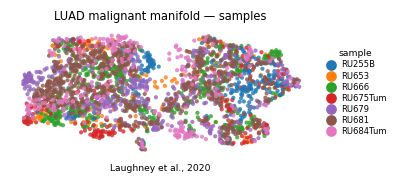

In [14]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('LUAD malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Laughney et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])